# Regresión: Lasso

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_REG, VARIANTES, N_ITER_REG, RUTA_FASE1_REG,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, dispositivo_reg, describir_espacio_reg,
    ejecutar_fase1_reg, formatear_tabla_cv_reg, tabla_hiperparametros_reg, graficar_variantes, evaluar_smearing,
    elegir_variante, guardar_fase1_reg, formatear_hiperparametros,
)

CLAVE = "lasso"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_reg(CLAVE),
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Lasso
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y_reg(df_train)
cv = crear_cv_reg(SEED)

resumen_target(y_train)

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.3,5.0,7.75,1.9,10.5,16.4


### Variantes del Target

| Variante | Qué se entrena | Cómo se predice |
|---|---|---|
| **a) Nativo** | `bdi_total` sin transformar (pérdida cuadrática) | Predicción directa |
| **b) sqrt** | $\sqrt{y}$ | $\hat y = \frac{1}{n}\sum_i (\hat z + e_i)^2$ (smearing) |
| **c) log1p** | $\log(1+y)$ | $\hat y = \frac{1}{n}\sum_i \left(e^{\hat z + e_i} - 1\right)$ (smearing) |

En las tres, la predicción final se recorta a $[0, 63]$.

**Sesgo de retransformación.** El modelo aprende la media **en la escala transformada**, $E[g(y)\mid x]$, y al deshacer la transformación se obtiene $g^{-1}(E[g(y)\mid x])$, que **no** es $E[y\mid x]$. Como las inversas ($z^2$ y $e^z - 1$) son convexas, por la desigualdad de Jensen la predicción retransformada **subestima la media** del BDI, más cuanto más dispersos son los residuos. Como el RMSE en puntos BDI premia acertar la media condicional, ese sesgo es un error sistemático.

**Corrección de smearing (Duan, 1983).** Se usan los residuos de entrenamiento en la escala transformada, $e_i = g(y_i) - \hat z_i$, como muestra de los errores posibles: $\hat y = \frac{1}{n}\sum_{i} g^{-1}(\hat z + e_i)$. `RegresorBDI` calcula los residuos **solo con los datos de entrenamiento de cada fold**. Todas las métricas se calculan en puntos BDI.

### Espacio de Búsqueda

Lasso puede dejar coeficientes exactamente en 0, así que también selecciona variables. Se exploraron 10 valores de `alpha` en escala logarítmica entre 1e-4 (prácticamente OLS) y 1e1. Con `alpha` grande todos los coeficientes quedan en 0 y el modelo predice la media del train; en las escalas sqrt y log1p eso ocurre con valores de `alpha` más pequeños, porque el target tiene menos varianza.

In [4]:
describir_espacio_reg(CLAVE).style.set_caption(f"Combinaciones por variante: {N_ITER_REG[CLAVE]}")

,Valores
Hiperparámetro,
alpha,log-uniforme entre 0.0001 y 10


### Validación Cruzada por Variante

Para cada variante se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` RMSE (`neg_root_mean_squared_error`). El RMSE, el MAE y el R² se calculan siempre en puntos BDI, nunca en la escala transformada.

In [5]:
tabla, pipelines, hiperparametros = ejecutar_fase1_reg(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo             RMSE = 6.8998 ± 0.4858  R² = 0.2011  (5 s)
✓ sqrt + smearing    RMSE = 6.9329 ± 0.4779  R² = 0.1932  (1 s)
✓ log1p + smearing   RMSE = 7.1391 ± 0.4987  R² = 0.1446  (1 s)


In [6]:
vista = formatear_tabla_cv_reg(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=VARIANTES)

,RMSE,MAE,R²,Tiempo (s)
Variante,,,,
Nativo,6.900 ± 0.486,4.906 ± 0.188,0.201 ± 0.016,5.0
sqrt + smearing,6.933 ± 0.478,4.917 ± 0.190,0.193 ± 0.018,1.0
log1p + smearing,7.139 ± 0.499,5.086 ± 0.199,0.145 ± 0.021,1.0


El nativo vuelve a ganar (RMSE = 6.900 ± 0.486, R² = 0.201 ± 0.016), igual que OLS y Ridge. sqrt queda a 0.03 puntos (6.933, R² = 0.193) y log1p es la peor (7.139, R² = 0.145), con el MAE más alto (5.086).

In [7]:
# Mejores hiperparámetros por variante
tabla_hiperparametros_reg(hiperparametros)

,alpha
Variante,
Nativo,0.007459
sqrt + smearing,0.007459
log1p + smearing,0.098470


El nativo y sqrt eligen el mismo `alpha` (0.0075), tan pequeño que el modelo es prácticamente OLS. log1p elige una penalización mayor (0.098), relativamente fuerte para un target que en esa escala solo varía entre 0 y 4.2.

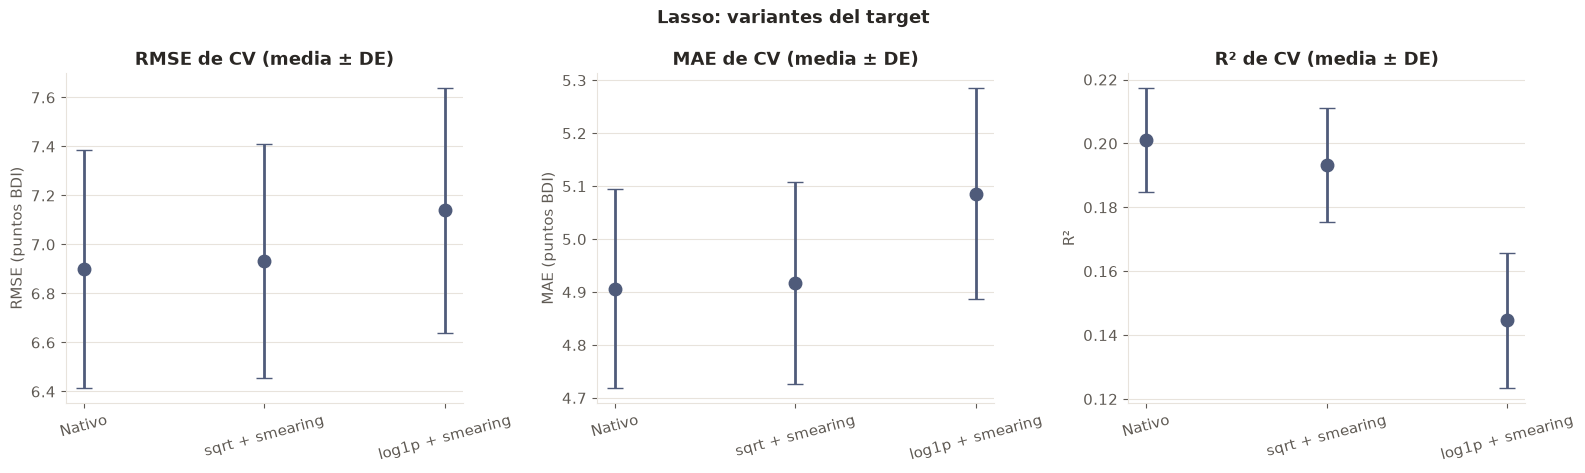

In [8]:
fig = graficar_variantes(tabla, NOMBRES_REG[CLAVE])
plt.show()

La gráfica muestra el mismo patrón que en OLS y Ridge: el nativo y sqrt son equivalentes y log1p es peor en las tres métricas.

### Sesgo de Retransformación: Efecto del Smearing

Con la mejor variante transformada se calculan predicciones *out-of-fold* (mismos folds, solo train) **con y sin** smearing. Sin la corrección, la media predicha debería quedar por debajo de la media real del BDI.

In [9]:
variante_t, tabla_smearing = evaluar_smearing(tabla, pipelines, X_train, y_train, cv)
tabla_smearing.round(3)

,Media,Sesgo medio,RMSE,MAE,R²
Out-of-fold (sqrt + smearing),,,,,
BDI real,7.302,0.000,NaN,NaN,NaN
Sin smearing,5.786,-1.516,7.113,4.670,0.157
Con smearing,7.268,-0.034,6.950,4.917,0.195


Sin smearing, la media predicha con sqrt es 5.79, 1.52 puntos por debajo de la real. Con la corrección queda en 7.27, el RMSE baja de 7.113 a 6.950 y el R² sube de 0.157 a 0.195. El MAE empeora (de 4.670 a 4.917) por la misma razón que en Ridge: el smearing lleva la predicción de la mediana a la media.

### Selección del Mejor Modelo Lasso

Se elige la variante con **menor RMSE medio de CV**.

**Regla de empate:** si una variante más simple (nativo < sqrt < log1p) queda a menos de una desviación estándar de CV de la ganadora, se elige la más simple.

In [10]:
variante_ganadora, explicacion = elegir_variante(tabla)

pd.Series({
    "Variante ganadora": VARIANTES[variante_ganadora],
    "RMSE de CV": f"{tabla.loc[variante_ganadora, 'RMSE media']:.4f} ± {tabla.loc[variante_ganadora, 'RMSE DE']:.4f}",
    "MAE de CV": f"{tabla.loc[variante_ganadora, 'MAE media']:.4f} ± {tabla.loc[variante_ganadora, 'MAE DE']:.4f}",
    "R² de CV": f"{tabla.loc[variante_ganadora, 'R² media']:.4f} ± {tabla.loc[variante_ganadora, 'R² DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[variante_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_REG[CLAVE]).to_frame()

,Lasso
Variante ganadora,Nativo
RMSE de CV,6.8998 ± 0.4858
MAE de CV,4.9062 ± 0.1875
R² de CV,0.2011 ± 0.0162
Hiperparámetros,alpha=0.007459
Criterio,Se elige 'Nativo': tiene el menor RMSE medio de CV (6.8998 ± 0.4858) y ninguna opción más simple queda a menos de una desviación estándar (0.4858).


Gana la variante nativa por menor RMSE medio (6.8998). Con `alpha` = 0.0075, Lasso casi no penaliza, así que es prácticamente idéntico a OLS.

### Guardado

In [11]:
ganador = guardar_fase1_reg(
    CLAVE, tabla, variante_ganadora, pipelines[variante_ganadora],
    hiperparametros[variante_ganadora], explicacion,
)
print(f"✓ Guardado en {RUTA_FASE1_REG / CLAVE}: resultados_cv.csv, ganador.json y {ganador['archivo']}")

✓ Guardado en /workspace/data/processed/modelado/regresion/fase1/lasso: resultados_cv.csv, ganador.json y lasso_nativo.joblib
